In [6]:
import pandas as pd
import numpy as np

import xgboost as xgb
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score, StratifiedKFold, permutation_test_score
from sklearn.metrics import classification_report, recall_score

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
import seaborn as sns


data_dir = '/home/lukeew/Local_work/data/01_SLW_xgb'
refrence_dir = data_dir + '/CHCH_v3_reference/'
reference_mask_dir = refrence_dir + 'processed{}/'

In [7]:
infile = refrence_dir + 'peaks_training_df.csv'
peaks_df = pd.read_csv(infile, index_col=[0]) 
print('  <--- ' + infile)

  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_reference/peaks_training_df.csv


In [8]:
## Filtering

peaks_df = peaks_df.dropna() # removes NaNs (e.g. no temperature data, so bad classification)

# Exclude case study dates from training dataset                           
exclusion_dates = [
    20210518,
    20210605,
    ]
                     
peaks_df = peaks_df[~peaks_df['date'].isin(exclusion_dates)]

peaks_df = peaks_df.reset_index(drop=True)

In [9]:
peaks_df

,date,peak_time_idx,peak_alt_idx,peak_magnitude,peak_width,peak_width_height,peak_prominence,peak_alt,num_peaks,peak_order,peak_temp,wlwc_target,slwc_target,slcc_target,mpc_target,ic_target,undet_target,unan_target
0,20210514,43,202,0.000025,5.021346,0.000013,0.000025,10.125,1,0,-53.570575,0,0,0,0,1,0,0
1,20210514,44,202,0.000022,5.433444,0.000011,0.000023,10.125,1,0,-53.569078,0,0,0,0,1,0,0
2,20210514,50,195,0.000020,18.462372,0.000010,0.000020,9.775,1,0,-52.376248,0,0,0,0,1,0,0
3,20210514,51,192,0.000023,16.217988,0.000012,0.000023,9.625,1,0,-51.669931,0,0,0,0,1,0,0
4,20210514,52,192,0.000020,1.588991,0.000020,0.000001,9.625,2,0,-51.700269,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
36762,20220120,284,63,0.000036,1.655835,0.000018,0.000036,3.175,1,0,-4.586685,0,0,0,0,0,0,1
36763,20220120,286,228,0.000026,3.522913,0.000013,0.000026,11.425,1,0,-54.901438,0,0,0,0,1,0,0
36764,20220121,35,53,0.000070,1.861522,0.000035,0.000070,2.675,1,0,-0.646539,0,1,1,0,0,0,0
36765,20220121,36,52,0.000105,1.742200,0.000052,0.000105,2.625,1,0,-0.414722,0,0,1,1,0,0,0


In [10]:
wlcw_peaks = peaks_df.query('wlwc_target == 1')
# no_wlwc_peaks = peaks_df.query('wlwc_target == 0')

slwc_peaks = peaks_df.query('slwc_target == 1')
# no_slwc_peaks = peaks_df.query('slwc_target == 0')

slcc_peaks = peaks_df.query('slcc_target == 1')
# no_slcc_peaks = peaks_df.query('slcc_target == 0')

mpc_peaks = peaks_df.query('mpc_target == 1')


ic_peaks = peaks_df.query('ic_target == 1')
# no_ic_peaks = peaks_df.query('ic_target == 0')

u_peaks = peaks_df.query('undet_target == 1')



In [ ]:
slcc_peaks

In [12]:
c1 = (0.03137254901960784,0.18823529411764706,0.4196078431372549,1)
c2 = (0.8,0,0,1)    
c3 = (0,0,1)
c4 = (0.8,0.8,0)
c5 = (0.7,0.7,0.7)


/tmp/ipykernel_901812/1896155899.py:28: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(wlcw_peaks[var],label='WLWC',ax=ax, color=c3,bins=30)
/home/lukeew/anaconda3/envs/01_SLW_xgb/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/tmp/ipykernel_901812/1896155899.py:29: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar 

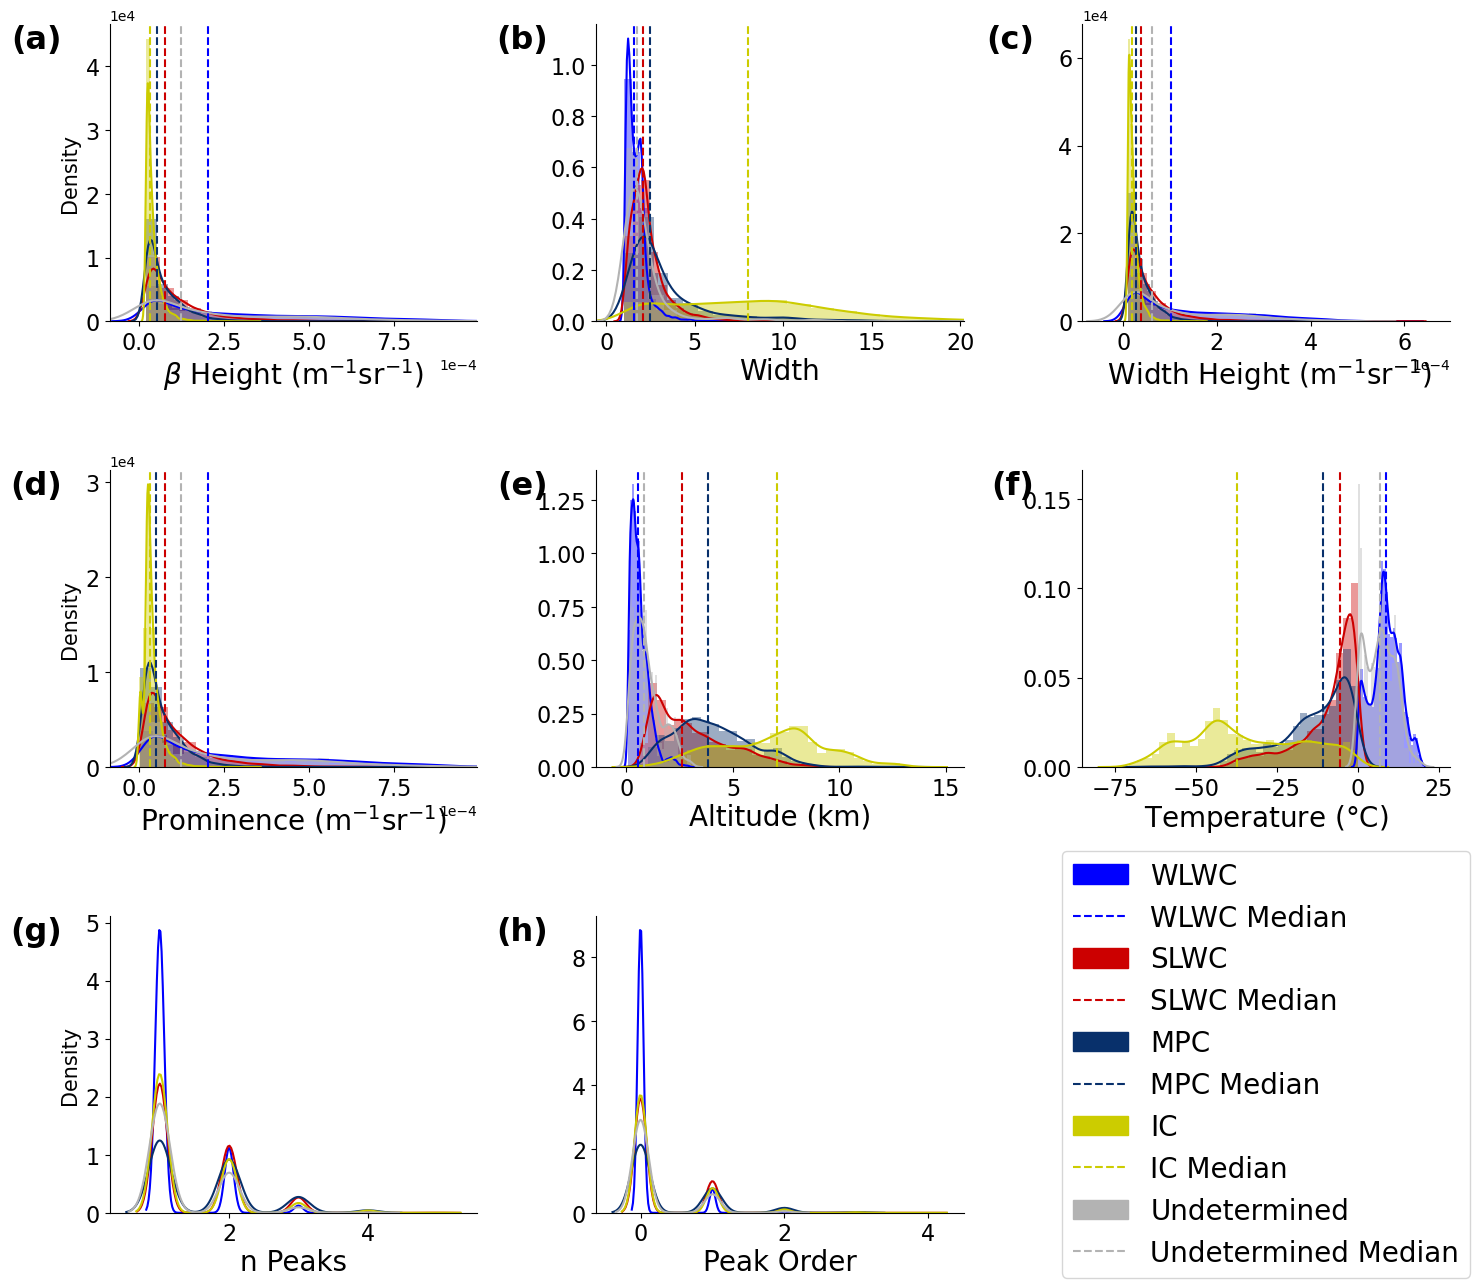

In [13]:
fig, axes = plt.subplots(3,3, figsize=(15,13))

var_list = ['peak_magnitude', 'peak_width', 'peak_width_height',
        'peak_prominence', 'peak_alt', 'peak_temp', 'num_peaks','peak_order',]

units_list = ['$\\beta$ Height (m$^{-1}$sr$^{-1}$)', 'Width', ' Width Height (m$^{-1}$sr$^{-1}$)',
        'Prominence (m$^{-1}$sr$^{-1}$)', 'Altitude (km)', 'Temperature ($\\degree$C)', 'n Peaks','Peak Order',]

letters='abcdefgh'

for i,var in enumerate(var_list):
    # print(var)
    
    ax = axes.flatten()[i]
    
    ax.tick_params(axis='both',which='major',labelsize=16)
    ax.tick_params(axis='both',which='minor',labelsize=16)
    
    ax.ticklabel_format(axis='x',style='sci',scilimits=(0,5))
    
    if var in ['num_peaks','peak_order']:
        sns.distplot(wlcw_peaks[var],label='WLWC',ax=ax, color=c3,bins=30,hist=False)
        sns.distplot(slwc_peaks[var],label='SLWC',ax=ax, color=c2,bins=30,hist=False)
        sns.distplot(mpc_peaks[var],label='MPC',ax=ax, color=c1,bins=30,hist=False)
        sns.distplot(ic_peaks[var],label='IC',ax=ax, color=c4,bins=30,hist=False)    
        sns.distplot(u_peaks[var],label='Un',ax=ax, color=c5,bins=30,hist=False)    
    else:
        sns.distplot(wlcw_peaks[var],label='WLWC',ax=ax, color=c3,bins=30)
        sns.distplot(slwc_peaks[var],label='SLWC',ax=ax, color=c2,bins=30)
        sns.distplot(mpc_peaks[var],label='MPC',ax=ax, color=c1,bins=30)
        sns.distplot(ic_peaks[var],label='IC',ax=ax, color=c4,bins=30)    
        sns.distplot(u_peaks[var],label='Un',ax=ax, color=c5,bins=30)    
    
        ax.axvline(np.nanmedian(wlcw_peaks[var]),c=c3,linestyle='--', label='WLWC Median')
        ax.axvline(np.nanmedian(slwc_peaks[var]),c=c2,linestyle='--', label='SLWC Median')
        ax.axvline(np.nanmedian(mpc_peaks[var]),c=c1,linestyle='--', label='MPC Median')
        ax.axvline(np.nanmedian(ic_peaks[var]),c=c4,linestyle='--', label='IC Median')
        ax.axvline(np.nanmedian(u_peaks[var]),c=c5,linestyle='--', label='Undetermined Median')
    
    unit = units_list[i]
    ax.set_xlabel(unit,fontsize=20,labelpad=2)
    # ax.set_title(var,fontsize=20)
    
    ax.ticklabel_format(axis='both',style='sci',scilimits=(-2,2))
    
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
        
    
    if i in [0,3,6]:
        ax.set_ylabel('Density', fontsize=15)
    else:
        ax.set_ylabel(' ')
            
    ax.text(-0.13,1,'({})'.format(letters[i]),fontsize=23,transform=ax.transAxes,ha='right',va='top',weight='semibold')
        
 
# print(axes[0,2].get_xlim())
axes[0,0].set_xlim(-8.789452652380182e-05, 0.0009970278532549434) #height
# axes[0,0].set_xlim(-8.789452652380182e-02, 0.9970278532549434) #height

axes[0,2].set_xlim(-8.789452652380182e-05, 0.0006970278532549434) #width height
axes[1,0].set_xlim(-8.789452652380182e-05, 0.0009970278532549434) #prom

axes[0,1].set_xlim(-0.6,20.2) # width
# axes[1,1].set_xlim(-1,9) # altitude

axes[2,2].axis('off')

colour_labels = ['WLWC','SLWC','MPC', 'IC', 'Undetermined']
patch_colors = [ c3,c2,c1, c4, c5]
patches_colours = [ mpatches.Patch(color=patch_colors[i], label=colour_labels[i] ) for i in range(5) ]

linestyle_labels = ['WLWC Median', 'SLWC Median','MPC Median','IC Median', 'Undetermined Median']
patches_lines = [mlines.Line2D([],[],color=patch_colors[i],linestyle='dashed', label=linestyle_labels[i]) for i in range(5)] 
patches = [patches_colours[0]] + [patches_lines[0]] + [patches_colours[1]] + [patches_lines[1]]  + [patches_colours[2]] + [patches_lines[2]] + [patches_colours[3]] + [patches_lines[3]] + [patches_colours[4]] + [patches_lines[4]]
# patches = patches_colours + patches_lines
axes[2,2].legend(handles=patches, loc='center', fontsize=20)#,borderaxespad=0. )
    
# plt.text(0.2,0.65,'# Liquid peaks   =    '+ str(len(LCC_peaks)),transform=axes[2,2].transAxes,fontsize=17)
# plt.text(0.2,0.55,'# Ice peaks = '+ str(len(ICC_peaks)),transform=axes[2,2].transAxes,fontsize=17)
plt.tight_layout()

# output_fpath = 'S://atmos_disk//Luke_W_480//MPL_Christchurch_2021//D//feature_dist/kde_all_update'
plt.show()

In [ ]:
## Altitude by width scatter plot

# q2_SLCC_all = np.empty(len(np.unique(peaks_df['peak_alt'])))
# q2_WLWC_all = np.empty(len(np.unique(peaks_df['peak_alt'])))
# q2_SLWC_all = np.empty(len(np.unique(peaks_df['peak_alt'])))
# q2_IC_all = np.empty(len(np.unique(peaks_df['peak_alt'])))


# for idx, alt in enumerate(np.unique(peaks_df['peak_alt'])):
#     peaks_df_alt = peaks_df.query('peak_alt=={}'.format(alt))
    
#     SLCC_peaks = peaks_df_alt.query('slcc_target == 1')
#     WLWC_peaks = peaks_df_alt.query('wlwc_target == 1')
#     SLWC_peaks = peaks_df_alt.query('slwc_target == 1')
#     IC_peaks = peaks_df_alt.query('ic_target == 1')

#     var = 'peak_width'
#     q2_SLCC = np.nanmedian(SLCC_peaks[var])
#     q2_WLWC = np.nanmedian(WLWC_peaks[var])
#     q2_SLWC = np.nanmedian(SLWC_peaks[var])
#     q2_ICLCC = np.nanmedian(IC_peaks[var])
    
#     q2_SLCC_all[idx]= q2_SLCC
#     q2_WLWC_all[idx]= q2_WLWC
#     q2_SLWC_all[idx]= q2_SLWC
#     q2_IC_all[idx]= q2_ICLCC

# plt.scatter(q2_IC_all,np.unique(peaks_df['peak_alt']),color=c1)
# plt.scatter(q2_WLWC_all,np.unique(peaks_df['peak_alt']),color=c2)